# Assignment 1: Data Profiling (EDA Report)

**Domain:** E-commerce / Retail

**Project Title:** Data Profiling and Quality Assessment of E-commerce Retail Transactions

### Group Members
- A207335 – ZHOU SHILI
- A207347 – LI DEXIN
- A207329 – DANG WENBIN

### 1. Scenario

An online retail company processes thousands of transactions involving different products, customers, and countries. However, the transaction data may contain missing values, duplicate records, unusual quantities, and invalid prices. This project aims to identify these data quality problems and apply suitable cleaning methods to improve the reliability of the dataset.

### 2. Data Source

- **Dataset:** Online Retail
- **Source:** UCI Machine Learning Repository
- **URL:** https://archive.ics.uci.edu/dataset/352/online+retail
- **Format:** Excel (.xlsx)
- **Collection Period:** December 2010 – December 2011

The dataset was downloaded from the UCI Machine Learning Repository and imported into Google Colab using Python and Pandas.

In [22]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")


Libraries imported successfully!


In [23]:

from google.colab import files

uploaded = files.upload()


Saving Online Retail.xlsx to Online Retail (2).xlsx


In [24]:

df = pd.read_excel("Online Retail.xlsx")

print("Dataset Shape:", df.shape)

display(df.head())


Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [25]:

print("DATASET INFORMATION")
print("=" * 50)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


DATASET INFORMATION
Number of rows: 541909
Number of columns: 8

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [26]:

print("First 5 Rows:")
display(df.head())

print("Last 5 Rows:")
display(df.tail())


First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Last 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [27]:

missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_values)


,Missing Count,Missing Percentage (%)
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


In [28]:

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

print("Duplicate percentage:",
      round(duplicate_count / len(df) * 100, 2), "%")


Number of duplicate rows: 5268
Duplicate percentage: 0.97 %


In [29]:

duplicate_rows = df[df.duplicated(keep=False)]

display(duplicate_rows.head(10))


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [30]:

print("Numerical Data Summary:")

display(
    df[["Quantity", "UnitPrice"]].describe()
)


Numerical Data Summary:


,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


### 3. Initial Data Profiling

The dataset contains 541,909 transaction records and 8 columns. The initial profiling process examined the dataset structure, missing values, duplicated records, and numerical statistics.

Missing values were found mainly in the CustomerID and Description columns. The dataset also contains duplicate records and unusual values in Quantity and UnitPrice.

These issues may affect the reliability of future retail analysis. Therefore, further investigation and appropriate data cleaning methods are required before the dataset can be considered suitable for analysis.

In [31]:

# Step 3.1: Detect Missing Values

missing_count = df.isnull().sum()
missing_percentage = df.isnull().mean() * 100

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_percentage.round(2)
})

print("Missing Values Report:")
display(missing_report)


Missing Values Report:


,Missing Count,Missing Percentage (%)
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


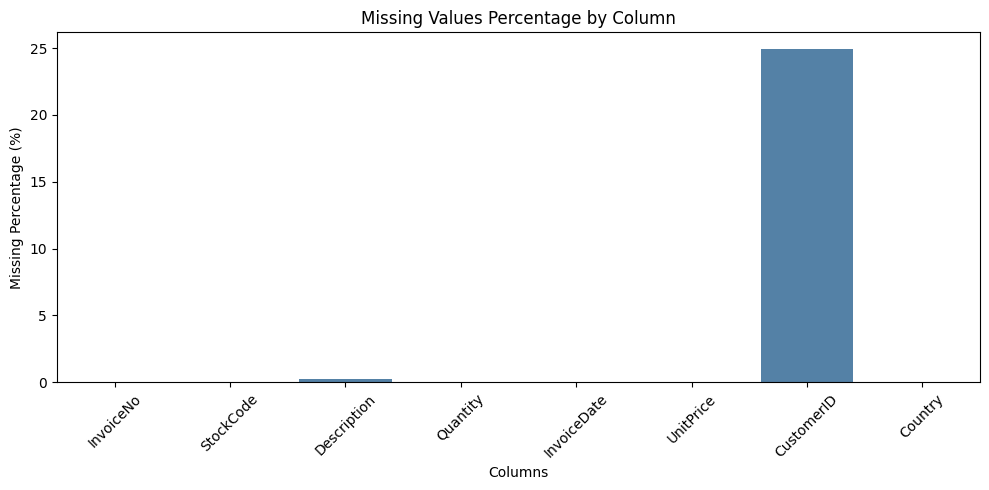

In [32]:

# Step 3.2: Missing Values Visualization

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_report.index,
    y=missing_report["Missing Percentage (%)"],
    color="steelblue"
)

plt.title("Missing Values Percentage by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [33]:

# Step 3.3: Handle Missing Values

df_clean = df.copy()

# Flag originally missing values
df_clean["MissingCustomerID"] = (
    df_clean["CustomerID"].isnull()
)

df_clean["MissingDescription"] = (
    df_clean["Description"].isnull()
)

# Fill missing product descriptions
df_clean["Description"] = (
    df_clean["Description"].fillna("Unknown Product")
)

# Keep missing CustomerID without inventing IDs

print("Missing values after handling:")
display(df_clean.isnull().sum())


Missing values after handling:


,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0
MissingCustomerID,0
MissingDescription,0


In [34]:

# Step 3.4: Before and After Comparison

comparison = pd.DataFrame({
    "Before Cleaning": df.isnull().sum(),
    "After Cleaning": df_clean[df.columns].isnull().sum()
})

print("Missing Values Before and After Cleaning:")
display(comparison)


Missing Values Before and After Cleaning:


,Before Cleaning,After Cleaning
InvoiceNo,0,0
StockCode,0,0
Description,1454,0
Quantity,0,0
InvoiceDate,0,0
UnitPrice,0,0
CustomerID,135080,135080
Country,0,0


### 3.1 Missing Values Detection and Handling

Missing values were detected using the Pandas `isnull()` function. The results showed that CustomerID and Description contained missing values.

CustomerID had approximately 24.93% missing values. These records were retained because they may still contain useful transaction information. A missing-value flag was added instead of removing the records.

Description had approximately 0.27% missing values. These missing values were replaced with "Unknown Product", and a flag was added to identify the original missing entries.

After cleaning, Description contained no missing values, while CustomerID missing values were intentionally retained.

This approach preserves useful transaction records and avoids unnecessary data loss.

In [35]:

# Step 4.1: Numerical Data Summary

print("Quantity and UnitPrice Statistics:")

display(df_clean[["Quantity", "UnitPrice"]].describe())


Quantity and UnitPrice Statistics:


,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [36]:

# Step 4.2: Detect Outliers Using IQR

def detect_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    print(f"\nColumn: {column}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))
    print("Outlier Percentage:",
          round(len(outliers) / len(data) * 100, 2), "%")

    return outliers, lower_bound, upper_bound


quantity_outliers, q_lower, q_upper = detect_outliers(
    df_clean, "Quantity"
)

price_outliers, p_lower, p_upper = detect_outliers(
    df_clean, "UnitPrice"
)



Column: Quantity
Q1: 1.0
Q3: 10.0
IQR: 9.0
Lower Bound: -12.5
Upper Bound: 23.5
Number of Outliers: 58619
Outlier Percentage: 10.82 %

Column: UnitPrice
Q1: 1.25
Q3: 4.13
IQR: 2.88
Lower Bound: -3.0700000000000003
Upper Bound: 8.45
Number of Outliers: 39627
Outlier Percentage: 7.31 %


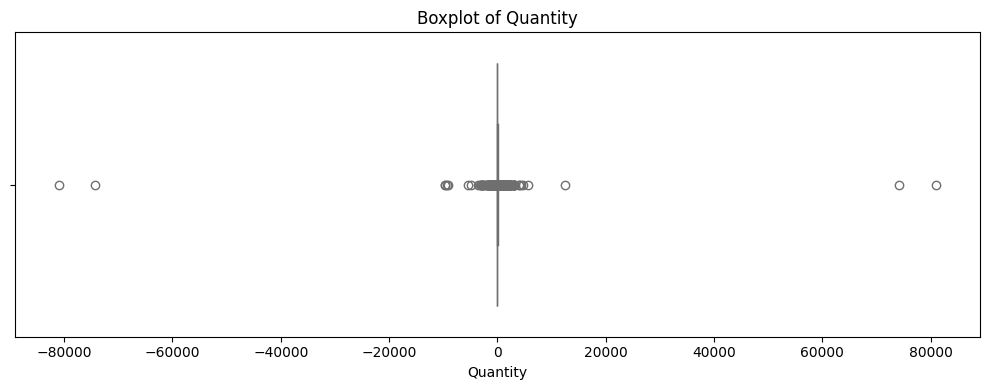

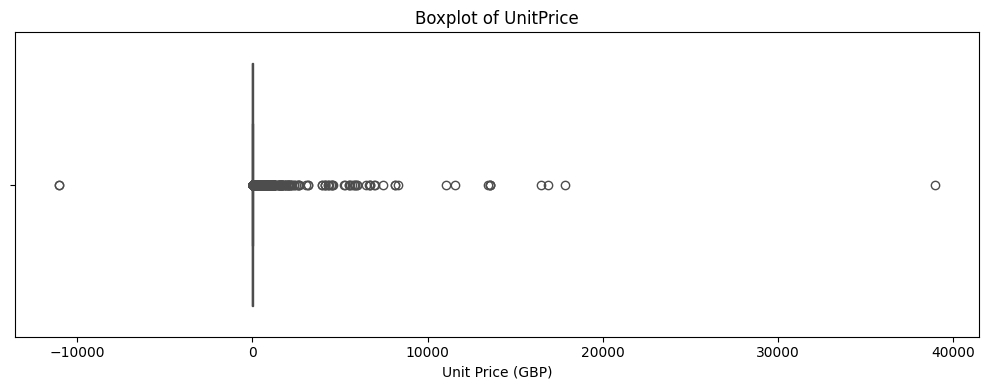

In [37]:

# Step 4.3: Boxplots for Outlier Detection

import matplotlib.pyplot as plt
import seaborn as sns

# Quantity Boxplot
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df_clean["Quantity"],
    color="skyblue"
)

plt.title("Boxplot of Quantity")
plt.xlabel("Quantity")
plt.tight_layout()
plt.show()


# UnitPrice Boxplot
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df_clean["UnitPrice"],
    color="orange"
)

plt.title("Boxplot of UnitPrice")
plt.xlabel("Unit Price (GBP)")
plt.tight_layout()
plt.show()


In [38]:

# Step 4.4: Handle Outliers by Flagging

df_clean["Quantity_Outlier"] = (
    (df_clean["Quantity"] < q_lower) |
    (df_clean["Quantity"] > q_upper)
)

df_clean["Price_Outlier"] = (
    (df_clean["UnitPrice"] < p_lower) |
    (df_clean["UnitPrice"] > p_upper)
)

# Flag potential cancellation records
df_clean["Is_Cancellation"] = (
    df_clean["InvoiceNo"]
    .astype(str)
    .str.upper()
    .str.startswith("C")
)

print("Quantity outliers:",
      df_clean["Quantity_Outlier"].sum())

print("Price outliers:",
      df_clean["Price_Outlier"].sum())

print("Cancellation records:",
      df_clean["Is_Cancellation"].sum())

print("\nSample flagged records:")
display(
    df_clean[
        df_clean["Quantity_Outlier"] |
        df_clean["Price_Outlier"]
    ].head(10)
)


Quantity outliers: 58619
Price outliers: 39627
Cancellation records: 9288

Sample flagged records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,MissingCustomerID,MissingDescription,Quantity_Outlier,Price_Outlier,Is_Cancellation
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom,False,False,True,False,False
16,536367,22622,BOX OF VINTAGE ALPHABET BLOCKS,2,2010-12-01 08:34:00,9.95,13047.0,United Kingdom,False,False,False,True,False
26,536370,22728,ALARM CLOCK BAKELIKE PINK,24,2010-12-01 08:45:00,3.75,12583.0,France,False,False,True,False,False
27,536370,22727,ALARM CLOCK BAKELIKE RED,24,2010-12-01 08:45:00,3.75,12583.0,France,False,False,True,False,False
30,536370,21883,STARS GIFT TAPE,24,2010-12-01 08:45:00,0.65,12583.0,France,False,False,True,False,False
31,536370,10002,INFLATABLE POLITICAL GLOBE,48,2010-12-01 08:45:00,0.85,12583.0,France,False,False,True,False,False
32,536370,21791,VINTAGE HEADS AND TAILS CARD GAME,24,2010-12-01 08:45:00,1.25,12583.0,France,False,False,True,False,False
34,536370,22326,ROUND SNACK BOXES SET OF4 WOODLAND,24,2010-12-01 08:45:00,2.95,12583.0,France,False,False,True,False,False
35,536370,22629,SPACEBOY LUNCH BOX,24,2010-12-01 08:45:00,1.95,12583.0,France,False,False,True,False,False
36,536370,22659,LUNCH BOX I LOVE LONDON,24,2010-12-01 08:45:00,1.95,12583.0,France,False,False,True,False,False


In [39]:

# Step 4.5: Outlier Handling Summary

outlier_summary = pd.DataFrame({
    "Column": ["Quantity", "UnitPrice"],
    "Outlier Count": [
        df_clean["Quantity_Outlier"].sum(),
        df_clean["Price_Outlier"].sum()
    ],
    "Handling Method": [
        "Flag and retain",
        "Flag and retain"
    ]
})

display(outlier_summary)

print("Original dataset rows:", len(df))
print("Current dataset rows:", len(df_clean))
print("No rows were removed during outlier handling.")


,Column,Outlier Count,Handling Method
0,Quantity,58619,Flag and retain
1,UnitPrice,39627,Flag and retain


Original dataset rows: 541909
Current dataset rows: 541909
No rows were removed during outlier handling.


### 3.2 Outlier Detection and Handling

Outliers were detected in the Quantity and UnitPrice columns using the Interquartile Range (IQR) method.

The IQR method identifies potential outliers based on values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. Boxplots were also created to visualize unusual values.

The results showed that both Quantity and UnitPrice contained extreme values. Some unusual quantities may represent wholesale orders, while negative quantities may indicate returned or cancelled transactions.

Instead of removing all outliers, this project applied a flagging approach. Two new columns, Quantity_Outlier and Price_Outlier, were created to identify potentially unusual transactions.

This approach was chosen because extreme values are not always data errors. Keeping these records helps avoid unnecessary data loss while allowing further investigation.

In [40]:

# Step 5.1: Detect Duplicate Records

# Use only the original dataset columns
original_columns = df.columns.tolist()

duplicate_count = df_clean.duplicated(
    subset=original_columns
).sum()

duplicate_percentage = (
    duplicate_count / len(df_clean) * 100
)

print("Duplicate Records Report")
print("Number of duplicates:", duplicate_count)
print("Duplicate percentage:",
      round(duplicate_percentage, 2), "%")

# Display sample duplicate rows
duplicate_rows = df_clean[
    df_clean.duplicated(
        subset=original_columns,
        keep=False
    )
]

display(duplicate_rows.head(10))


Duplicate Records Report
Number of duplicates: 5268
Duplicate percentage: 0.97 %


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,MissingCustomerID,MissingDescription,Quantity_Outlier,Price_Outlier,Is_Cancellation
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,False,False,False,False,False
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,False,False,False,False,False
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,False,False,False,False,False
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,False,False,False,False,False
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,False,False,False,False,False
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,False,False,False,False,False
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,False,False,False,False,False
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,False,False,False,False,False
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,False,False,False,False,False
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,False,False,False,False,False


In [41]:

# Step 5.2: Handle Duplicate Records

df_clean["Is_Duplicate"] = (
    df_clean.duplicated(
        subset=original_columns,
        keep=False
    )
)

print("Rows belonging to duplicate groups:",
      df_clean["Is_Duplicate"].sum())

print("Dataset rows after handling:",
      len(df_clean))

print("Duplicates were flagged, not removed.")


Rows belonging to duplicate groups: 10147
Dataset rows after handling: 541909
Duplicates were flagged, not removed.


In [42]:

# Step 5.3: Check Data Types

print("Data Types Before Cleaning:")
display(df_clean.dtypes)


Data Types Before Cleaning:


,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object
MissingCustomerID,bool
MissingDescription,bool


In [43]:

# Step 5.4: Correct Data Types

df_clean["InvoiceNo"] = (
    df_clean["InvoiceNo"].astype("string")
)

df_clean["StockCode"] = (
    df_clean["StockCode"].astype("string")
)

df_clean["Description"] = (
    df_clean["Description"].astype("string")
)

df_clean["Country"] = (
    df_clean["Country"].astype("string")
)

df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"],
    errors="coerce"
)

df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"],
    errors="coerce"
)

df_clean["CustomerID"] = pd.to_numeric(
    df_clean["CustomerID"],
    errors="coerce"
).astype("Int64")

print("Data Types After Cleaning:")
display(df_clean.dtypes)


Data Types After Cleaning:


,0
InvoiceNo,string[python]
StockCode,string[python]
Description,string[python]
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,Int64
Country,string[python]
MissingCustomerID,bool
MissingDescription,bool


In [44]:

# Step 5.5: Check Inconsistent Formats

print("Country values before formatting:")
display(df_clean["Country"].value_counts().head(15))

# Count rows with leading/trailing whitespace
text_columns = [
    "InvoiceNo", "StockCode",
    "Description", "Country"
]

for col in text_columns:
    values = df_clean[col].dropna()
    space_count = (
        values != values.str.strip()
    ).sum()

    print(f"{col} - Extra whitespace: {space_count}")


Country values before formatting:


,count
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519


InvoiceNo - Extra whitespace: 0
StockCode - Extra whitespace: 0
Description - Extra whitespace: 113452
Country - Extra whitespace: 0


In [45]:

# Step 5.5: Clean Inconsistent Formats

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

# Standardize product descriptions
# without forcing uppercase/lowercase changes
df_clean["Description"] = (
    df_clean["Description"]
    .str.replace(r"\s+", " ", regex=True)
)

print("Country values after formatting:")
display(df_clean["Country"].value_counts().head(15))

print("Text formatting completed.")


Country values after formatting:


,count
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519


Text formatting completed.


In [46]:

# Step 5.6: Detect Invalid Values

invalid_quantity = (
    df_clean["Quantity"] <= 0
).sum()

invalid_price = (
    df_clean["UnitPrice"] < 0
).sum()

zero_price = (
    df_clean["UnitPrice"] == 0
).sum()

invalid_date = (
    df_clean["InvoiceDate"].isna()
).sum()

print("Invalid / Suspicious Values Report")
print("Non-positive Quantity:", invalid_quantity)
print("Negative UnitPrice:", invalid_price)
print("Zero UnitPrice:", zero_price)
print("Missing/Invalid Dates:", invalid_date)


Invalid / Suspicious Values Report
Non-positive Quantity: 10624
Negative UnitPrice: 2
Zero UnitPrice: 2515
Missing/Invalid Dates: 0


In [47]:

# Step 5.7: Handle Invalid Values

# Flag suspicious records
df_clean["Invalid_Quantity"] = (
    df_clean["Quantity"] <= 0
)

df_clean["Invalid_Price"] = (
    df_clean["UnitPrice"] < 0
)

df_clean["Zero_Price"] = (
    df_clean["UnitPrice"] == 0
)

df_clean["Invalid_Date"] = (
    df_clean["InvoiceDate"].isna()
)

# Create a positive-sales subset
df_sales = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0) &
    (~df_clean["Is_Cancellation"]) &
    (df_clean["InvoiceDate"].notna())
].copy()

print("Original rows:", len(df))
print("Full profiled rows:", len(df_clean))
print("Positive sales rows:", len(df_sales))

print("Rows excluded from sales subset:",
      len(df_clean) - len(df_sales))


Original rows: 541909
Full profiled rows: 541909
Positive sales rows: 530104
Rows excluded from sales subset: 11805


In [48]:

# Step 5.8: Data Quality Summary

quality_summary = pd.DataFrame({
    "Quality Issue": [
        "Exact Duplicate Rows",
        "Non-positive Quantity",
        "Negative UnitPrice",
        "Zero UnitPrice",
        "Invalid InvoiceDate"
    ],
    "Count": [
        duplicate_count,
        invalid_quantity,
        invalid_price,
        zero_price,
        invalid_date
    ],
    "Handling Method": [
        "Flag and retain",
        "Exclude from positive-sales subset",
        "Exclude from positive-sales subset",
        "Exclude from positive-sales subset",
        "Exclude from positive-sales subset"
    ]
})

print("Data Quality Summary:")
display(quality_summary)


Data Quality Summary:


,Quality Issue,Count,Handling Method
0,Exact Duplicate Rows,5268,Flag and retain
1,Non-positive Quantity,10624,Exclude from positive-sales subset
2,Negative UnitPrice,2,Exclude from positive-sales subset
3,Zero UnitPrice,2515,Exclude from positive-sales subset
4,Invalid InvoiceDate,0,Exclude from positive-sales subset


### 3.3 Other Data Quality Issues

Several additional data quality issues were investigated, including duplicate records, incorrect data types, inconsistent text formats, and invalid values.

**Duplicate Records:** Exact duplicate records were detected using the Pandas `duplicated()` function. These records were flagged instead of automatically deleted because identical transaction rows may represent legitimate purchases.

**Wrong Data Types:** Data types were checked and corrected where necessary. InvoiceDate was converted to datetime format, CustomerID to nullable integer format, and identifier and text fields to string format.

**Inconsistent Formats:** Leading and trailing whitespace was removed from text fields. Extra spaces in product descriptions were also standardized to improve consistency.

**Invalid Values:** Non-positive quantities, negative prices, zero prices, and invalid dates were identified. Some records may represent returns, cancellations, or special transactions rather than data entry errors.

A separate positive-sales dataset was created by excluding cancelled transactions, non-positive quantities, non-positive prices, and invalid dates. The full dataset was retained with quality flags to preserve the original transaction information.

These methods improve data consistency while reducing the risk of unnecessary information loss.

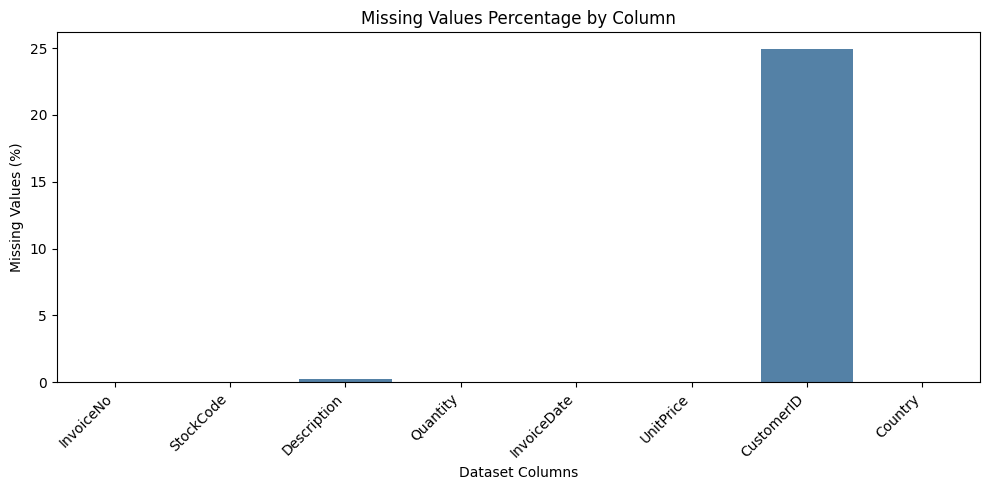

In [49]:

# Step 6.1: Missing Values Chart

import matplotlib.pyplot as plt
import seaborn as sns

missing_pct = df.isnull().mean() * 100

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_pct.index,
    y=missing_pct.values,
    color="steelblue"
)

plt.title("Missing Values Percentage by Column")
plt.xlabel("Dataset Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("missing_values_chart.png", dpi=300)
plt.show()


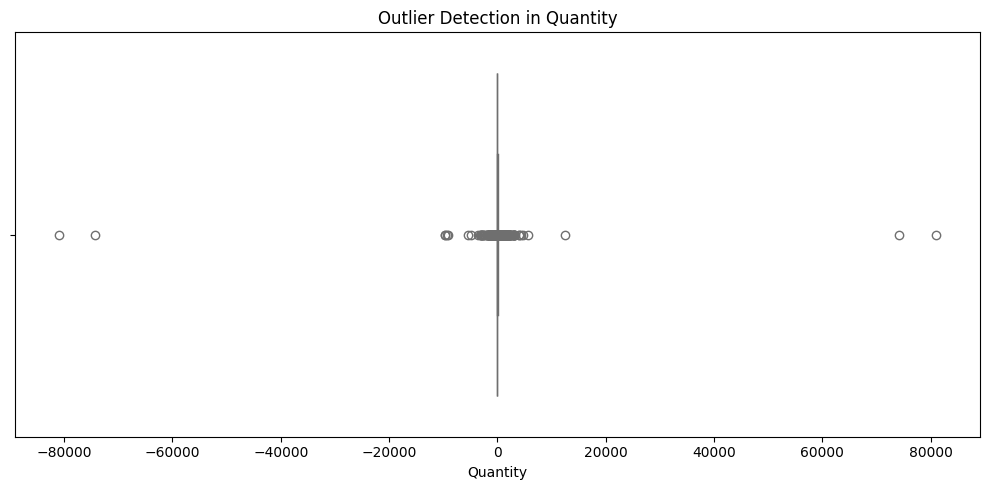

In [50]:

# Step 6.2: Quantity Outlier Boxplot

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["Quantity"],
    color="skyblue"
)

plt.title("Outlier Detection in Quantity")
plt.xlabel("Quantity")
plt.tight_layout()

plt.savefig("quantity_outliers.png", dpi=300)
plt.show()


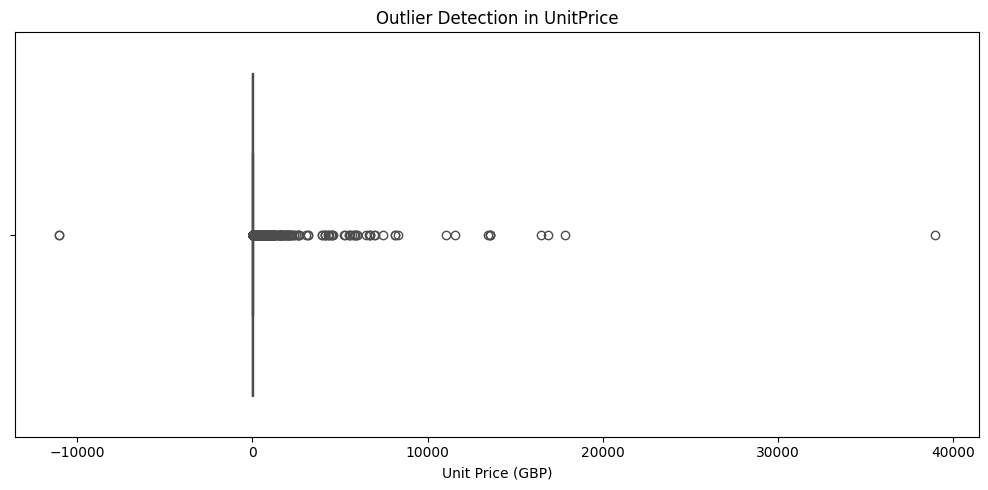

In [51]:

# Step 6.3: UnitPrice Outlier Boxplot

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["UnitPrice"],
    color="orange"
)

plt.title("Outlier Detection in UnitPrice")
plt.xlabel("Unit Price (GBP)")
plt.tight_layout()

plt.savefig("unitprice_outliers.png", dpi=300)
plt.show()


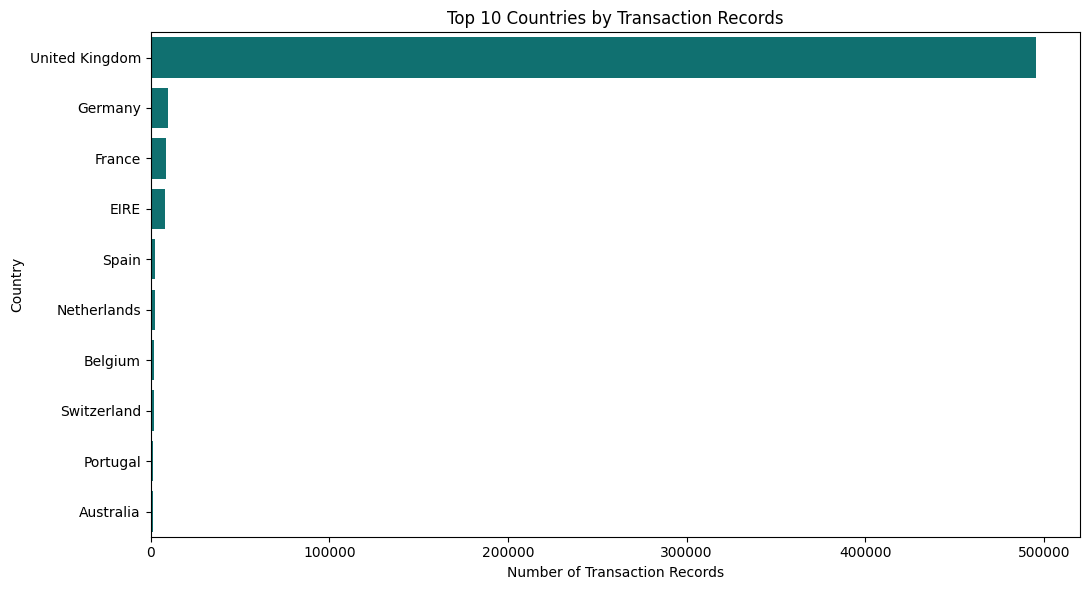

In [52]:

# Step 6.4: Country Distribution Chart

country_counts = (
    df["Country"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=country_counts.values,
    y=country_counts.index,
    color="teal"
)

plt.title("Top 10 Countries by Transaction Records")
plt.xlabel("Number of Transaction Records")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig("country_distribution.png", dpi=300)
plt.show()


In [53]:

# Step 6.5: Diagnostic Statistics

print("DIAGNOSTIC CHART SUMMARY")
print("=" * 45)

print("\n1. Missing Values")
print((df.isnull().mean() * 100).round(2))

print("\n2. Quantity Outliers")
print("Count:", df_clean["Quantity_Outlier"].sum())
print("Percentage:",
      round(df_clean["Quantity_Outlier"].mean() * 100, 2))

print("\n3. UnitPrice Outliers")
print("Count:", df_clean["Price_Outlier"].sum())
print("Percentage:",
      round(df_clean["Price_Outlier"].mean() * 100, 2))

print("\n4. Country Distribution")
print(df["Country"].value_counts().head(10))

uk_percentage = (
    df["Country"].eq("United Kingdom").mean() * 100
)

print("\nUnited Kingdom Percentage:",
      round(uk_percentage, 2), "%")


DIAGNOSTIC CHART SUMMARY

1. Missing Values
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64

2. Quantity Outliers
Count: 58619
Percentage: 10.82

3. UnitPrice Outliers
Count: 39627
Percentage: 7.31

4. Country Distribution
Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

United Kingdom Percentage: 91.43 %


### 4. Exploratory Diagnostic Charts

Four diagnostic charts were created to identify and explain data quality issues in the Online Retail dataset.

**Figure 1: Missing Values Percentage by Column**

The missing-value chart shows that CustomerID has the highest percentage of missing values, approximately 24.93%. This indicates that customer information is incomplete for a considerable number of transactions.

**Figure 2: Outlier Detection in Quantity**

The quantity boxplot shows the presence of extreme values. Some unusually large quantities may represent wholesale orders, while negative quantities may indicate returns or cancellations. These values were flagged for further investigation.

**Figure 3: Outlier Detection in UnitPrice**

The price boxplot shows extreme values in the UnitPrice column. Some unusual prices may represent special transactions or data quality problems. Therefore, these values were flagged rather than automatically removed.

**Figure 4: Top 10 Countries by Transaction Records**

The country distribution chart shows that transaction records are heavily concentrated in the United Kingdom. This indicates a potential geographical sampling bias, as the dataset may not represent global online retail activity.

Overall, these visualizations provide evidence of missing information, potential outliers, and geographical imbalance. They support the data cleaning decisions and help identify limitations in the dataset.

In [54]:

# Step 7.1: Check Potential PII

print("PII Risk Assessment")
print("=" * 45)

print("Total records:", len(df_clean))

print("Missing CustomerID:",
      df_clean["CustomerID"].isna().sum())

print("Unique CustomerIDs:",
      df_clean["CustomerID"].nunique())

print("Unique Invoice Numbers:",
      df_clean["InvoiceNo"].nunique())

print("\nPotential PII Fields:")
pii_fields = [
    "CustomerID",
    "InvoiceNo",
    "InvoiceDate",
    "Country"
]

print(pii_fields)


PII Risk Assessment
Total records: 541909
Missing CustomerID: 135080
Unique CustomerIDs: 4372
Unique Invoice Numbers: 25900

Potential PII Fields:
['CustomerID', 'InvoiceNo', 'InvoiceDate', 'Country']


In [55]:

# Step 7.2: Pseudonymize CustomerID

import hashlib

# Create a separate dataset for privacy protection
df_private = df_clean.copy()

def pseudonymize_customer(customer_id):
    if pd.isna(customer_id):
        return pd.NA

    value = str(int(customer_id))

    return hashlib.sha256(
        value.encode("utf-8")
    ).hexdigest()[:16]

df_private["CustomerID_Hashed"] = (
    df_private["CustomerID"]
    .apply(pseudonymize_customer)
    .astype("string")
)

# Remove original customer identifiers
df_private = df_private.drop(columns=["CustomerID"])

print("CustomerID pseudonymization completed.")

display(
    df_private[
        ["CustomerID_Hashed", "Country"]
    ].head(10)
)


CustomerID pseudonymization completed.


,CustomerID_Hashed,Country
0,8072f6579de32612,United Kingdom
1,8072f6579de32612,United Kingdom
2,8072f6579de32612,United Kingdom
3,8072f6579de32612,United Kingdom
4,8072f6579de32612,United Kingdom
5,8072f6579de32612,United Kingdom
6,8072f6579de32612,United Kingdom
7,8072f6579de32612,United Kingdom
8,8072f6579de32612,United Kingdom
9,8182553da16df7cc,United Kingdom


In [56]:

# Step 7.3: Geographic Bias Analysis

country_distribution = (
    df_clean["Country"]
    .value_counts()
    .reset_index()
)

country_distribution.columns = [
    "Country",
    "Transaction Count"
]

country_distribution["Percentage (%)"] = (
    country_distribution["Transaction Count"]
    / len(df_clean) * 100
).round(2)

print("Country Distribution:")
display(country_distribution.head(15))


Country Distribution:


,Country,Transaction Count,Percentage (%)
0,United Kingdom,495478,91.43
1,Germany,9495,1.75
2,France,8557,1.58
3,EIRE,8196,1.51
4,Spain,2533,0.47
5,Netherlands,2371,0.44
6,Belgium,2069,0.38
7,Switzerland,2002,0.37
8,Portugal,1519,0.28
9,Australia,1259,0.23


In [57]:

# Step 7.3: UK vs Other Countries

uk_count = (
    df_clean["Country"] == "United Kingdom"
).sum()

other_count = len(df_clean) - uk_count

uk_percentage = uk_count / len(df_clean) * 100
other_percentage = other_count / len(df_clean) * 100

print("United Kingdom:", uk_count)
print("Other Countries:", other_count)

print("UK Percentage:",
      round(uk_percentage, 2), "%")

print("Other Countries Percentage:",
      round(other_percentage, 2), "%")


United Kingdom: 495478
Other Countries: 46431
UK Percentage: 91.43 %
Other Countries Percentage: 8.57 %


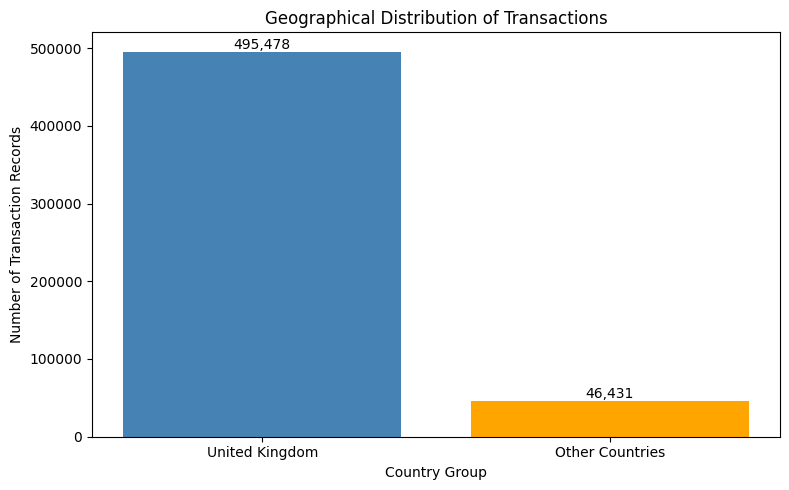

In [58]:

# Step 7.4: Geographic Bias Chart

import matplotlib.pyplot as plt

labels = ["United Kingdom", "Other Countries"]
counts = [uk_count, other_count]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    labels,
    counts,
    color=["steelblue", "orange"]
)

plt.title("Geographical Distribution of Transactions")
plt.xlabel("Country Group")
plt.ylabel("Number of Transaction Records")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("geographic_bias.png", dpi=300)
plt.show()


In [59]:

# Step 7.5: PII and Bias Risk Summary

risk_summary = pd.DataFrame({
    "Risk Type": [
        "PII",
        "PII",
        "PII",
        "Geographical Bias",
        "Historical Data Bias"
    ],
    "Affected Field": [
        "CustomerID",
        "InvoiceNo",
        "InvoiceDate",
        "Country",
        "InvoiceDate"
    ],
    "Potential Risk": [
        "Customer re-identification",
        "Transaction linkage",
        "Customer behavior tracking",
        "UK market overrepresentation",
        "Outdated purchasing patterns"
    ],
    "Handling Method": [
        "Pseudonymization",
        "Restrict access",
        "Reduce timestamp precision",
        "Report country imbalance",
        "State dataset limitations"
    ]
})

print("PII and Bias Risk Summary:")
display(risk_summary)


PII and Bias Risk Summary:


,Risk Type,Affected Field,Potential Risk,Handling Method
0,PII,CustomerID,Customer re-identification,Pseudonymization
1,PII,InvoiceNo,Transaction linkage,Restrict access
2,PII,InvoiceDate,Customer behavior tracking,Reduce timestamp precision
3,Geographical Bias,Country,UK market overrepresentation,Report country imbalance
4,Historical Data Bias,InvoiceDate,Outdated purchasing patterns,State dataset limitations


### 5. PII and Bias Risks

**5.1 Personally Identifiable Information (PII)**

The Online Retail dataset contains fields that may introduce privacy risks, including CustomerID, InvoiceNo, InvoiceDate, and Country.

Although CustomerID does not directly reveal a customer's name, it can be used to link multiple transactions belonging to the same customer. Invoice numbers and transaction dates may also reveal purchasing patterns when combined with other information.

To reduce privacy risks, CustomerID was pseudonymized using a hashing method in a separate dataset. The original customer identifiers were removed from that version. However, pseudonymization does not guarantee complete anonymity, so further access controls would still be necessary.

**5.2 Geographical Bias**

The dataset contains transactions from multiple countries, but a large proportion of records comes from the United Kingdom.

This imbalance creates potential geographical sampling bias because the overall patterns may mainly reflect the UK retail market rather than global online retail activity.

Instead of removing records to artificially balance the dataset, the original country distribution was retained and the geographical limitation was documented.

**5.3 Historical Data Limitation**

The dataset covers transactions between December 2010 and December 2011. Consumer behavior and online shopping patterns may have changed since then.

Therefore, the dataset is useful for demonstrating data profiling and cleaning methods, but its findings should not be generalized directly to current e-commerce markets.

**5.4 Risk Mitigation**

The following measures were considered to reduce privacy and bias risks:

- Pseudonymize customer identifiers and restrict access to transaction-level data.
- Avoid publishing unnecessary identifiers and detailed transaction timestamps.
- Report geographical imbalances and interpret findings within the dataset's scope.
- Acknowledge that historical retail data may not represent current customer behavior.

These measures improve the responsible use of the dataset and make its limitations more transparent.

In [60]:

# Step 8.1: Final Data Quality Report

import pandas as pd

final_report = pd.DataFrame({
    "Data Quality Issue": [
        "Missing CustomerID",
        "Missing Description",
        "Exact Duplicate Rows",
        "Quantity Outliers (IQR)",
        "UnitPrice Outliers (IQR)",
        "Non-positive Quantity",
        "Negative UnitPrice",
        "Zero UnitPrice",
        "Invalid InvoiceDate"
    ],
    "Original Count": [
        df["CustomerID"].isna().sum(),
        df["Description"].isna().sum(),
        df.duplicated().sum(),
        df_clean["Quantity_Outlier"].sum(),
        df_clean["Price_Outlier"].sum(),
        (df["Quantity"] <= 0).sum(),
        (df["UnitPrice"] < 0).sum(),
        (df["UnitPrice"] == 0).sum(),
        pd.to_datetime(
            df["InvoiceDate"],
            errors="coerce"
        ).isna().sum()
    ],
    "Handling Method": [
        "Retain and flag",
        "Fill with Unknown Product and flag",
        "Retain and flag",
        "Retain and flag",
        "Retain and flag",
        "Separate from positive sales",
        "Exclude from positive sales",
        "Exclude from positive sales",
        "Exclude from positive sales"
    ]
})

print("FINAL DATA QUALITY REPORT")
display(final_report)


FINAL DATA QUALITY REPORT


,Data Quality Issue,Original Count,Handling Method
0,Missing CustomerID,135080,Retain and flag
1,Missing Description,1454,Fill with Unknown Product and flag
2,Exact Duplicate Rows,5268,Retain and flag
3,Quantity Outliers (IQR),58619,Retain and flag
4,UnitPrice Outliers (IQR),39627,Retain and flag
5,Non-positive Quantity,10624,Separate from positive sales
6,Negative UnitPrice,2,Exclude from positive sales
7,Zero UnitPrice,2515,Exclude from positive sales
8,Invalid InvoiceDate,0,Exclude from positive sales


In [61]:

# Step 8.2: Before and After Comparison

comparison_report = pd.DataFrame({
    "Dataset Version": [
        "Original Dataset",
        "Profiled Dataset",
        "Positive Sales Dataset"
    ],
    "Number of Rows": [
        len(df),
        len(df_clean),
        len(df_sales)
    ],
    "Number of Columns": [
        len(df.columns),
        len(df_clean.columns),
        len(df_sales.columns)
    ],
    "Purpose": [
        "Raw transaction records",
        "Transactions with quality flags",
        "Valid positive-sales subset"
    ]
})

print("BEFORE AND AFTER COMPARISON")
display(comparison_report)

print("\nOriginal Rows:", len(df))
print("Positive Sales Rows:", len(df_sales))

print("Excluded from Positive Sales:",
      len(df) - len(df_sales))

print("Positive Sales Retention Rate:",
      round(len(df_sales) / len(df) * 100, 2),
      "%")


BEFORE AND AFTER COMPARISON


,Dataset Version,Number of Rows,Number of Columns,Purpose
0,Original Dataset,541909,8,Raw transaction records
1,Profiled Dataset,541909,18,Transactions with quality flags
2,Positive Sales Dataset,530104,18,Valid positive-sales subset



Original Rows: 541909
Positive Sales Rows: 530104
Excluded from Positive Sales: 11805
Positive Sales Retention Rate: 97.82 %


In [62]:

# Step 8.3: Export Final Results

final_report.to_csv(
    "final_data_quality_report.csv",
    index=False
)

comparison_report.to_csv(
    "before_after_comparison.csv",
    index=False
)

df_sales.to_csv(
    "online_retail_positive_sales.csv",
    index=False
)

print("Files exported successfully!")


Files exported successfully!


### 6. Conclusion

This project examined the quality of the Online Retail dataset using Python and Pandas. The data profiling process identified several issues, including missing values, potential duplicate records, unusual quantities, extreme prices, and privacy risks.

Missing product descriptions were replaced with "Unknown Product", while missing customer identifiers were retained and flagged to avoid losing useful transaction information.

The IQR method was used to detect outliers in Quantity and UnitPrice. These outliers were flagged rather than automatically removed because some extreme values may represent legitimate wholesale transactions.

Duplicate records were also flagged for further investigation. Data types and text formatting were standardized, and a separate positive-sales dataset was created by excluding cancellation records, non-positive quantities, non-positive prices, and invalid dates.

The privacy assessment highlighted potential customer identification risks, while the bias analysis showed that the dataset was mainly concentrated in the United Kingdom.

Overall, the positive-sales dataset is more suitable for ordinary retail sales analysis. However, missing customer information, unresolved duplicate records, geographical imbalance, and historical data limitations remain. Further validation would be needed before using the data for business decision-making.